# Axe 11 : typologie des secteurs et des départements

Les graphes des axes 8 et 9 regroupaient les secteurs et les départements selon la **forme** de leur courbe de défaillances. Ici, on les regroupe autrement : chacun est décrit par **quelques indicateurs** de défaillance, et on applique un **clustering** (k-means et classification hiérarchique, TP2). À la fin, on compare les groupes obtenus avec les communautés des graphes.

### Les 5 indicateurs

| Indicateur | En clair |
|---|---|
| **Taux de défaillance 2017-2019** | Entreprises entrées en défaillance par an, pour 1 000 entreprises actives au 1er janvier, en moyenne avant le Covid. |
| **Part de liquidations directes** | Parmi les entrées en défaillance, la part qui est une liquidation directe (et pas un redressement) : l'entreprise est jugée impossible à sauver dès le départ. |
| **Effet Covid** | Entrées en défaillance 2020-2021, divisées par celles de 2017-2019 (moyennes annuelles). 0,6 = 40 % de défaillances en moins. |
| **Rattrapage** | Entrées 2023-2025 divisées par celles de 2017-2019. Au-dessus de 1, on dépasse le niveau d'avant crise. |
| **Part de jeunes** | Part des entreprises défaillantes qui ont moins de 3 ans au jugement. |

### Les décisions

| Sujet | Décision | Qui |
|---|---|---|
| Indicateurs | Les 5 indicateurs ci-dessus. Le taux, l'effet Covid et le rattrapage sont des **rapports** : on les passe en **log** (×2 et ÷2 deviennent symétriques), sinon un seul secteur extrême (les boissons, dont les défaillances ont été multipliées par 6 au rattrapage) forme un groupe à lui seul. Puis centrage-réduction. | Luka |
| Périmètre | Les secteurs (divisions NAF) et départements avec au moins **500 défaillances**, comme aux axes 8 et 9. | Luka |
| Nombre de groupes | **4** pour les secteurs comme pour les départements. Départements : la meilleure silhouette. Secteurs : un compromis, car la silhouette est maximale à k = 3 (0,241, presque égale à 0,238 pour k = 4) et le coude de l'inertie est à k = 5. | Luka |

## 1. Calcul des indicateurs (DuckDB, à partir de la table de faits du cube)

In [1]:
import sys
sys.path.append("../../scripts")

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from data_utils import PROCESSED, RAW, NAF_DIVISIONS
import graphe_utils as gu

DASH = PROCESSED.parent / "dashboard"
con = duckdb.connect()
con.execute("SET memory_limit = '3GB'")
FAITS, SIRENE = PROCESSED / "cube_faits.parquet", PROCESSED / "sirene_clean.parquet"

def indicateurs(col_faits, col_sirene):
    entrees = con.execute(f"""
        SELECT {col_faits} AS cle,
               count(DISTINCT siren) FILTER (WHERE annee BETWEEN 2017 AND 2019) / 3.0 AS entrees_17_19,
               count(DISTINCT siren) FILTER (WHERE annee BETWEEN 2020 AND 2021) / 2.0 AS entrees_20_21,
               count(DISTINCT siren) FILTER (WHERE annee BETWEEN 2023 AND 2025) / 3.0 AS entrees_23_25,
               avg(CASE WHEN nature ILIKE '%liquidation%' THEN 1.0 WHEN nature ILIKE '%redressement%' THEN 0.0 END) AS part_lj_directe,
               avg(CASE WHEN tranche_age IN ('< 1 an', '1-3 ans') THEN 1.0
                        WHEN tranche_age <> 'non renseigné' THEN 0.0 END) AS part_jeunes,
               count(*) AS entrees_total
        FROM read_parquet('{FAITS}')
        WHERE categorie = 'entrée en défaillance' AND {col_faits} <> 'non renseigné'
        GROUP BY ALL""").df().set_index("cle")
    actives = con.execute(f"""
        WITH s AS (SELECT CAST({col_sirene} AS VARCHAR) AS cle, year(date_creation) AS c,
                          CASE WHEN active THEN NULL ELSE year(date_debut) END AS f, active, date_debut
                   FROM read_parquet('{SIRENE}') WHERE {col_sirene} IS NOT NULL)
        SELECT cle, avg(n) AS actives_17_19 FROM (
            SELECT cle, a.annee, count(*) AS n FROM s
            JOIN (SELECT range AS annee FROM range(2017, 2020)) a
              ON s.c < a.annee AND (s.active OR (s.date_debut IS NOT NULL AND s.f >= a.annee))
            GROUP BY ALL) GROUP BY cle""").df().set_index("cle")
    t = entrees.join(actives)
    t["taux 2017-2019 (‰)"] = 1000 * t["entrees_17_19"] / t["actives_17_19"]
    t["effet Covid"] = t["entrees_20_21"] / t["entrees_17_19"]
    t["rattrapage"] = t["entrees_23_25"] / t["entrees_17_19"]
    t = t.rename(columns={"part_lj_directe": "part LJ directe", "part_jeunes": "part de jeunes"})
    return t.sort_index()   # DuckDB ne renvoie pas toujours les lignes dans le même ordre : on trie pour des résultats reproductibles

INDIC = ["taux 2017-2019 (‰)", "part LJ directe", "effet Covid", "rattrapage", "part de jeunes"]
sect = indicateurs("naf_division", "naf_division")
dep = indicateurs("departement", "departement")
sect = sect[sect["entrees_total"] >= 500].dropna(subset=INDIC)
dep = dep[dep["entrees_total"] >= 500].dropna(subset=INDIC)
print(len(sect), "secteurs |", len(dep), "départements")
sect.assign(secteur=sect.index.map(NAF_DIVISIONS))[["secteur", *INDIC]].sort_values("taux 2017-2019 (‰)", ascending=False).head(12).round(2)

62 secteurs | 100 départements


,secteur,taux 2017-2019 (‰),part LJ directe,effet Covid,rattrapage,part de jeunes
cle,,,,,,
80,Enquêtes et sécurité,19.46,0.67,0.62,1.16,0.24
56,Restauration,17.59,0.66,0.47,1.23,0.36
10,Industries alimentaires,16.94,0.59,0.45,1.18,0.28
43,Travaux de construction spécialisés,11.69,0.69,0.52,1.14,0.28
45,Commerce et réparation automobile,11.12,0.72,0.64,1.32,0.28
61,Télécommunications,10.85,0.75,0.60,1.71,0.23
41,Construction de bâtiments,10.20,0.73,0.60,1.30,0.27
25,Fabrication de produits métalliques,10.11,0.49,0.62,1.17,0.16
49,Transports terrestres,10.07,0.70,0.59,1.42,0.21


### Observations

- On garde **62 secteurs** et **100 départements**, comme aux axes 8 et 9.
- Les secteurs les plus touchés avant le Covid sont l'**enquête et la sécurité** (19,5 ‰ par an), la **restauration** (17,6 ‰) et les **industries alimentaires** (16,9 ‰), loin devant la construction (10 à 12 ‰).

In [2]:
# Les indicateurs sont-ils liés entre eux ? (Spearman, sur les secteurs)
sect[INDIC].corr(method="spearman").round(2)

,taux 2017-2019 (‰),part LJ directe,effet Covid,rattrapage,part de jeunes
taux 2017-2019 (‰),1.00,0.04,-0.30,-0.22,0.26
part LJ directe,0.04,1.00,0.10,0.06,0.58
effet Covid,-0.30,0.10,1.00,0.57,0.00
rattrapage,-0.22,0.06,0.57,1.00,0.07
part de jeunes,0.26,0.58,0.00,0.07,1.00


### Observations

- Les indicateurs sont assez **indépendants** entre eux : ils apportent chacun une information différente.
- Deux liens ressortent : l'**effet Covid** et le **rattrapage** vont ensemble (0,57) : les secteurs les moins protégés pendant le Covid sont aussi ceux qui rattrapent le plus. Et la **part de jeunes** va avec la **part de liquidations directes** (0,58) : là où les entreprises défaillantes sont jeunes, on les liquide plus souvent tout de suite.

## 2. Outils de clustering

In [3]:
def preparer(t):
    """Log des rapports (taux, effet Covid, rattrapage), puis centrage-réduction."""
    X = t[INDIC].copy()
    for c in ["taux 2017-2019 (‰)", "effet Covid", "rattrapage"]:
        X[c] = np.log(X[c])
    return StandardScaler().fit_transform(X)

def par_taille(etiquettes):
    """Renumérote les groupes par taille décroissante (1 = le plus grand) : la numérotation reste stable d'une exécution à l'autre."""
    ordre = pd.Series(etiquettes).value_counts().index
    return pd.Series(etiquettes).map({g: i + 1 for i, g in enumerate(ordre)}).to_numpy()

def choisir_k(Xs, ks=range(2, 9)):
    lignes = []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=20, random_state=0).fit(Xs)
        lignes.append({"k": k, "inertie": km.inertia_, "silhouette": silhouette_score(Xs, km.labels_)})
    return pd.DataFrame(lignes).set_index("k")

def decrire(t, groupes, nom):
    d = t[INDIC].groupby(groupes).median()
    d.insert(0, "nombre", pd.Series(groupes).value_counts())
    gros = t["entrees_total"].sort_values(ascending=False).index
    d["les plus grands"] = [", ".join(nom(x) for x in gros if x in set(t.index[groupes == g]))[:110] for g in d.index]
    return d

def dendro(Xs, etiquettes, titre):
    Zl = linkage(Xs, method="ward")
    fig, ax = plt.subplots(figsize=(14, 4.2))
    dendrogram(Zl, labels=etiquettes, leaf_font_size=6.5, color_threshold=None, above_threshold_color=gu.GRIS, ax=ax)
    ax.set_title(titre, loc="left", fontsize=11, color=gu.TITRE)
    ax.grid(False)
    plt.show()
    return Zl

## 3. Les secteurs

In [4]:
Xs = preparer(sect)
choix_s = choisir_k(Xs)
print("coude de l'inertie : k =", gu.coude(choix_s.index, choix_s["inertie"]))
choix_s.round(3)

coude de l'inertie : k = 5.0


,inertie,silhouette
k,,
2,234.139,0.220
3,188.635,0.241
4,156.799,0.238
5,131.165,0.223
6,115.656,0.205
7,103.757,0.219
8,96.956,0.206


### Observations

- La silhouette reste **modeste** (0,21 à 0,24) : les groupes de secteurs ne sont pas très séparés. Elle est maximale à k = 3 (0,241), presque à égalité avec k = 4 (0,238). Le coude de l'inertie est à k = 5.

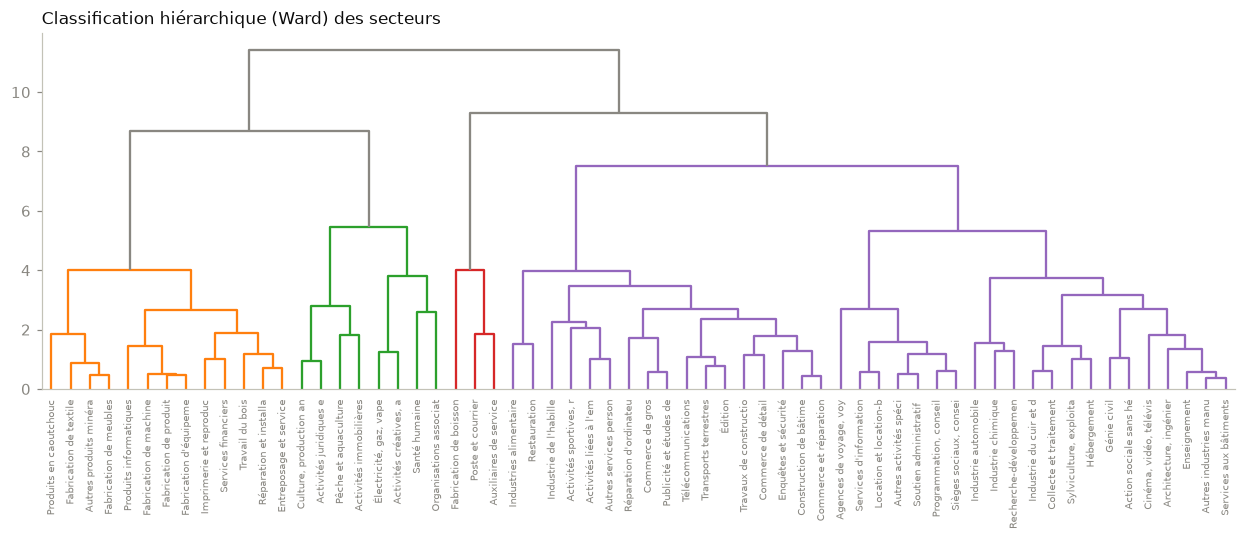

ARI k-means / classification hiérarchique : 0.509


,nombre,taux 2017-2019 (‰),part LJ directe,effet Covid,rattrapage,part de jeunes,les plus grands
1,31,4.49,0.73,0.61,1.30,0.24,"Travaux de construction spécialisés, Commerce ..."
2,22,6.48,0.58,0.59,1.17,0.18,"Industries alimentaires, Services financiers, ..."
3,6,0.73,0.50,0.73,1.39,0.10,"Activités immobilières, Culture, production an..."
4,3,1.72,0.69,0.87,2.84,0.26,Auxiliaires de services financiers et d'assura...


In [5]:
KS = 4
km_s = KMeans(n_clusters=KS, n_init=20, random_state=0).fit(Xs)
sect["groupe"] = par_taille(km_s.labels_)
Z_s = dendro(Xs, [NAF_DIVISIONS[d][:22] for d in sect.index], "Classification hiérarchique (Ward) des secteurs")
sect["groupe CAH"] = fcluster(Z_s, KS, criterion="maxclust")
print("ARI k-means / classification hiérarchique :", round(adjusted_rand_score(sect["groupe"], sect["groupe CAH"]), 3))
decrire(sect, sect["groupe"].to_numpy(), lambda d: NAF_DIVISIONS[d]).round(2)

### Observations

- k-means et la classification hiérarchique (Ward) donnent des groupes **moyennement proches** (ARI 0,51).
- **Groupe 4 – « rattrapage explosif »** (3 secteurs : auxiliaires financiers, poste, boissons) : peu de défaillances avant le Covid, mais **presque 3 fois plus** en 2023-2025 qu'en 2017-2019.
- **Groupe 2 – « industrie et services techniques »** (22 secteurs, surtout l'industrie, plus l'hébergement et les services financiers) : taux élevé avant le Covid (6,5 ‰), mais **moins de liquidations directes** (58 %) et moins de jeunes entreprises (18 %). On y tente plus souvent un redressement.
- **Groupe 1 – « commerce, construction, services »** (31 secteurs, dont les plus grands : construction, commerce, restauration) : taux de 4,5 ‰, beaucoup de **liquidations directes** (73 %), un rattrapage net (+30 % par rapport à 2017-2019).
- **Groupe 3 – « peu de défaillances »** (6 secteurs : immobilier, agriculture, santé, associations, professions juridiques, pêche) : un taux très bas (0,7 ‰), la moitié seulement de liquidations directes (50 %) et très peu de jeunes entreprises (10 %).

In [6]:
for g in sorted(sect["groupe"].unique()):
    membres = sect[sect["groupe"] == g].sort_values("entrees_total", ascending=False).index
    print(f"Groupe {g} ({len(membres)}) : " + " · ".join(NAF_DIVISIONS[d] for d in membres))

Groupe 1 (31) : Travaux de construction spécialisés · Commerce de détail · Restauration · Commerce de gros · Commerce et réparation automobile · Autres services personnels · Transports terrestres · Construction de bâtiments · Sièges sociaux, conseil de gestion · Services aux bâtiments, aménagement paysager · Architecture, ingénierie, contrôle technique · Programmation, conseil informatique · Enseignement · Soutien administratif aux entreprises · Enquêtes et sécurité · Activités sportives, récréatives et de loisirs · Autres activités spécialisées, scientifiques et techniques · Publicité et études de marché · Location et location-bail · Réparation d'ordinateurs et de biens personnels · Édition · Cinéma, vidéo, télévision, musique enregistrée · Activités créatives, artistiques et de spectacle · Industrie de l'habillement · Autres industries manufacturières · Services d'information · Télécommunications · Agences de voyage, voyagistes · Activités liées à l'emploi · Collecte et traitement de

## 4. Les secteurs : comparaison avec les communautés du graphe (axe 8)

In [7]:
g8 = pd.read_parquet(DASH / "graphe_secteurs_noeuds.parquet").set_index("division")["communauté"]
commun = sect.index.intersection(g8.index)
print(f"secteurs dans les deux analyses : {len(commun)} | ARI groupes / communautés du graphe : "
      f"{adjusted_rand_score(sect.loc[commun, 'groupe'], g8.loc[commun]):.3f}")
pd.crosstab(sect.loc[commun, "groupe"], g8.loc[commun], rownames=["groupe (indicateurs)"], colnames=["communauté (graphe)"])

secteurs dans les deux analyses : 51 | ARI groupes / communautés du graphe : 0.003


communauté (graphe),1,2,3,4
groupe (indicateurs),,,,
1,5,7,9,4
2,6,8,3,2
3,4,0,1,0
4,1,0,1,0


### Observations

- Les groupes trouvés avec les indicateurs **ne correspondent pas** aux communautés du graphe (ARI 0,003). Les deux analyses regardent des choses différentes : le graphe compare la **forme des courbes** dans le temps, la typologie compare des **niveaux** (taux, part de liquidations…). Elles se complètent.

## 5. Les départements

In [8]:
Xd = preparer(dep)
noms_dep, polys = gu.charger_departements(RAW / "geo" / "departements.geojson")
choix_d = choisir_k(Xd)
print("coude de l'inertie : k =", gu.coude(choix_d.index, choix_d["inertie"]))
choix_d.round(3)

coude de l'inertie : k = 5.0


,inertie,silhouette
k,,
2,403.474,0.195
3,340.228,0.210
4,282.250,0.233
5,245.340,0.230
6,223.826,0.205
7,202.460,0.219
8,185.637,0.189


### Observations

- Pour les départements, la meilleure silhouette est à **k = 4** (0,23), le coude de l'inertie à k = 5. Là aussi, les groupes sont peu séparés.

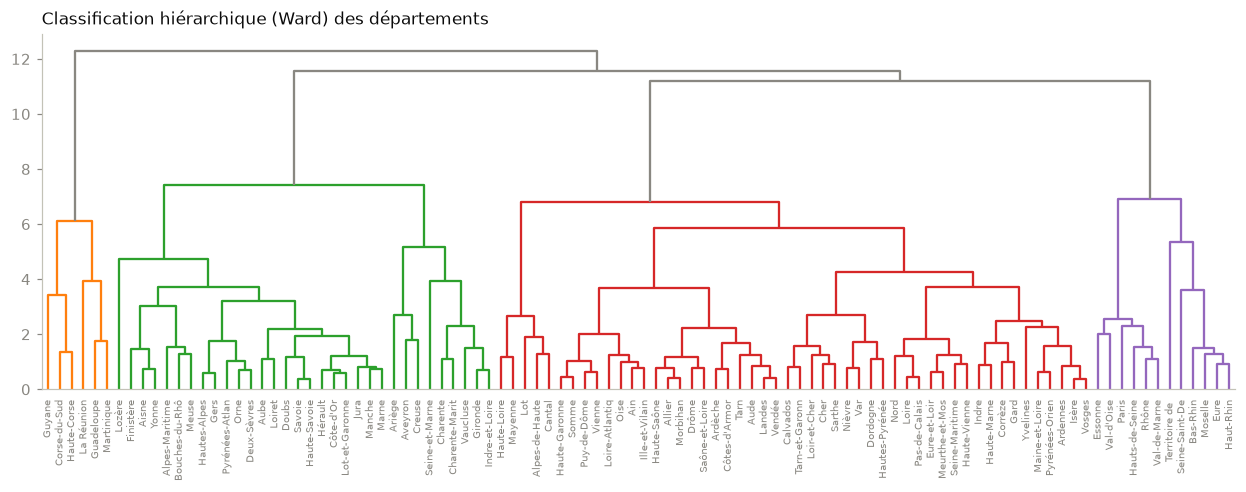

ARI k-means / classification hiérarchique : 0.619


,nombre,taux 2017-2019 (‰),part LJ directe,effet Covid,rattrapage,part de jeunes,les plus grands
1,46,3.69,0.66,0.49,1.14,0.29,"Nord, Var, Isère, Moselle, Pas-de-Calais, Yvel..."
2,39,3.23,0.62,0.60,1.26,0.28,"Bouches-du-Rhône, Gironde, Alpes-Maritimes, Se..."
3,9,4.47,0.83,0.57,1.25,0.24,"Paris, Seine-Saint-Denis, Rhône, Hauts-de-Sein..."
4,6,3.67,0.51,0.52,1.16,0.13,"La Réunion, Martinique, Guadeloupe, Corse-du-S..."


In [9]:
KD = 4
km_d = KMeans(n_clusters=KD, n_init=20, random_state=0).fit(Xd)
dep["groupe"] = par_taille(km_d.labels_)
Z_d = dendro(Xd, [noms_dep.get(d, d)[:14] for d in dep.index], "Classification hiérarchique (Ward) des départements")
dep["groupe CAH"] = fcluster(Z_d, KD, criterion="maxclust")
print("ARI k-means / classification hiérarchique :", round(adjusted_rand_score(dep["groupe"], dep["groupe CAH"]), 3))
decrire(dep, dep["groupe"].to_numpy(), lambda d: noms_dep.get(d, d)).round(2)

### Observations

- k-means et la classification hiérarchique sont **assez d'accord** (ARI 0,62).
- **Groupe 3 – « grandes agglomérations et Alsace »** (9 départements : Paris, Hauts-de-Seine, Seine-Saint-Denis, Val-de-Marne, Essonne, Val-d'Oise, Rhône, Bas-Rhin, Haut-Rhin) : le taux le plus élevé (4,5 ‰) et surtout **83 % de liquidations directes**.
- **Groupe 4 – « outre-mer et Corse »** (6 départements : Guadeloupe, Martinique, Guyane, La Réunion, Corse-du-Sud, Haute-Corse) : peu de liquidations directes (51 %) et très peu de jeunes entreprises défaillantes (13 %).
- **Groupes 1 et 2** (46 et 39 départements) : ils se ressemblent et se distinguent surtout par le **Covid** : le groupe 1 a eu moins de défaillances pendant le Covid (effet 0,49 contre 0,60) et rattrape moins (1,14 contre 1,26).

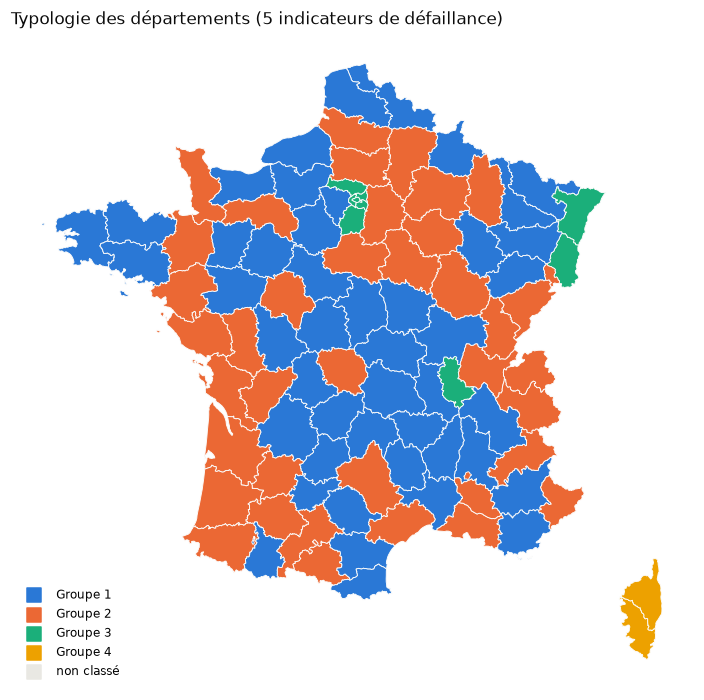

départements voisins dans le même groupe : 51.3% | toutes paires confondues : 39.8%


In [10]:
groupe_dep = dep["groupe"].to_dict()
legende = [(f"Groupe {g}", gu.COULEURS[(g - 1) % 8]) for g in sorted(dep["groupe"].unique())] + [("non classé", "#e9e8e3")]
gu.carte_departements(polys, lambda d: gu.COULEURS[(groupe_dep[d] - 1) % 8] if d in groupe_dep else None,
                      "Typologie des départements (5 indicateurs de défaillance)", legende=legende)
plt.show()
voisins = gu.voisins_geographiques(polys)
metro = [d for d in dep.index if d in polys]
paires_voisines = [(a, b) for a, b in voisins if a in groupe_dep and b in groupe_dep]
meme_v = np.mean([groupe_dep[a] == groupe_dep[b] for a, b in paires_voisines])
meme_h = np.mean([groupe_dep[a] == groupe_dep[b] for i, a in enumerate(metro) for b in metro[i + 1:]])
print(f"départements voisins dans le même groupe : {meme_v:.1%} | toutes paires confondues : {meme_h:.1%}")

### Observations

- Sur la carte, les groupes forment davantage de **taches** que les communautés du graphe : **51 %** des départements voisins sont dans le même groupe, contre 40 % pour deux départements pris au hasard. La géographie joue un peu plus ici.

In [11]:
g9 = pd.read_parquet(DASH / "graphe_departements_noeuds.parquet").set_index("departement")["communauté"]
commun_d = dep.index.intersection(g9.index)
print(f"départements dans les deux analyses : {len(commun_d)} | ARI groupes / communautés du graphe : "
      f"{adjusted_rand_score(dep.loc[commun_d, 'groupe'], g9.loc[commun_d]):.3f}")

départements dans les deux analyses : 94 | ARI groupes / communautés du graphe : 0.024


### Observations

- Comme pour les secteurs, la typologie et les communautés du graphe **ne se recoupent pas** (ARI 0,02) : ce sont deux lectures différentes et complémentaires.

## 6. Export pour le dashboard

In [12]:
out_s = sect[[*INDIC, "groupe", "entrees_total"]].reset_index(names="division")
out_s["secteur"] = out_s["division"].map(NAF_DIVISIONS)
out_s.to_parquet(DASH / "typologie_secteurs.parquet", index=False)
out_d = dep[[*INDIC, "groupe", "entrees_total"]].reset_index(names="departement")
out_d["nom"] = out_d["departement"].map(lambda d: noms_dep.get(d, d))
out_d.to_parquet(DASH / "typologie_departements.parquet", index=False)
con.close()
print("export : typologie_secteurs, typologie_departements")

export : typologie_secteurs, typologie_departements
